# DDPM From Scratch in PyTorch

A complete compact DDPM pipeline for MNIST: data preparation, forward diffusion, timestep-conditioned U-Net, noise-prediction training, checkpoint/resume, reverse sampling, and visual diagnostics. Run top to bottom; the first run may download MNIST. Training time and sample quality depend on the device and configuration. No pretrained weights are used.

## 1. Environment and device

Imports, reports library versions, and selects CUDA when available.

In [1]:
import math, random
from pathlib import Path
from typing import Optional
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
NumPy: 2.1.3
CUDA available: True
Selected device: cuda


## 2. Configuration and reproducibility

Adjust all key hyperparameters in this cell. `epochs` is the target completed epoch count; set `resume=True` to continue from the checkpoint if it exists.

In [2]:
CONFIG = {
    "seed": 42, "batch_size": 128, "epochs": 20, "learning_rate": 2e-4,
    "num_timesteps": 300, "beta_start": 1e-4, "beta_end": 0.02,
    "base_channels": 32, "num_workers": 2, "checkpoint_dir": "checkpoints",
    "checkpoint_name": "ddpm_mnist.pt", "resume": False,
    "sample_every_epochs": 1, "sample_count": 16, "show_progress": True,
}
SEED = int(CONFIG["seed"])
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
BATCH_SIZE = int(CONFIG["batch_size"])
NUM_TIMESTEPS = int(CONFIG["num_timesteps"])
CHECKPOINT_DIR = Path(CONFIG["checkpoint_dir"]); CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / CONFIG["checkpoint_name"]
print("Checkpoint:", CHECKPOINT_PATH)

Checkpoint: checkpoints/ddpm_mnist.pt


## 3. MNIST dataset

`ToTensor` maps pixels to `[0,1]`; normalization maps them to `[-1,1]`. The loader shuffles examples and pins memory on CUDA.

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 506kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.37MB/s]


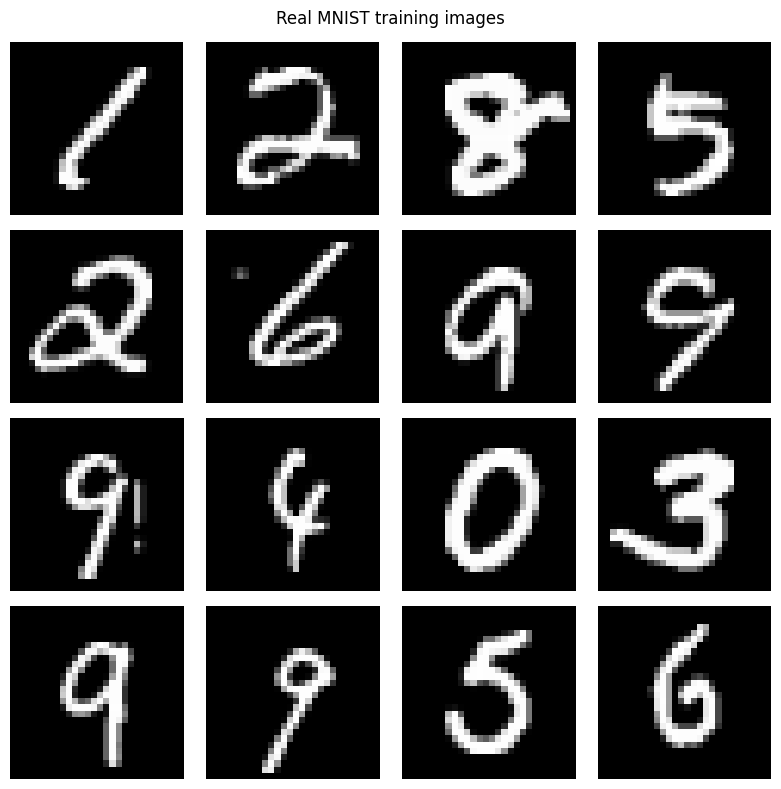

In [3]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_dataset = datasets.MNIST("./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=int(CONFIG["num_workers"]), pin_memory=(device.type == "cuda"), drop_last=False)
real_images, real_labels = next(iter(train_loader))
assert real_images.ndim == 4 and tuple(real_images.shape[1:]) == (1, 28, 28)
assert real_images.min() >= -1.01 and real_images.max() <= 1.01

def show_image_grid(images: torch.Tensor, title: str, nrow: int = 4) -> None:
    images = images.detach().cpu().clamp(-1, 1)
    rows = math.ceil(len(images) / nrow)
    fig, axes = plt.subplots(rows, nrow, figsize=(2*nrow, 2*rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images): ax.imshow(images[i, 0], cmap="gray", vmin=-1, vmax=1)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_image_grid(real_images[:16], "Real MNIST training images")

## 4. Linear noise schedule

`betas` is the added variance; `alphas=1-betas`; `alpha_bars` is the cumulative product. Square-root arrays implement forward diffusion. `posterior_variance` is the variance of `q(x[t-1]|x[t],x[0])`. Every schedule tensor has shape `[T]`; `extract` gathers per-image timesteps and reshapes to `[B,1,1,1]` for broadcasting.

In [4]:
def make_noise_schedule(T: int, beta_start: float, beta_end: float, device: torch.device):
    assert T >= 2
    betas = torch.linspace(beta_start, beta_end, T, device=device, dtype=torch.float32)
    assert torch.all((betas > 0) & (betas < 1))
    alphas = 1. - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.)
    sqrt_alpha_bars = torch.sqrt(alpha_bars)
    sqrt_one_minus_alpha_bars = torch.sqrt(1. - alpha_bars)
    posterior_variance = (betas * (1. - alpha_bars_prev) / (1. - alpha_bars)).clamp(min=1e-20)
    return {"betas":betas, "alphas":alphas, "alpha_bars":alpha_bars,
        "alpha_bars_prev":alpha_bars_prev, "sqrt_alpha_bars":sqrt_alpha_bars,
        "sqrt_one_minus_alpha_bars":sqrt_one_minus_alpha_bars,
        "posterior_variance":posterior_variance}

schedule = make_noise_schedule(NUM_TIMESTEPS, float(CONFIG["beta_start"]), float(CONFIG["beta_end"]), device)
for name, value in schedule.items():
    assert value.shape == (NUM_TIMESTEPS,) and value.device.type == device.type
    print(name, tuple(value.shape), value.device)

def extract(values: torch.Tensor, t: torch.Tensor, x_shape: torch.Size) -> torch.Tensor:
    assert t.ndim == 1 and t.dtype == torch.long and x_shape[0] == t.shape[0]
    return values.gather(0, t).reshape(t.shape[0], *((1,) * (len(x_shape)-1)))

betas (300,) cuda:0
alphas (300,) cuda:0
alpha_bars (300,) cuda:0
alpha_bars_prev (300,) cuda:0
sqrt_alpha_bars (300,) cuda:0
sqrt_one_minus_alpha_bars (300,) cuda:0
posterior_variance (300,) cuda:0


## 5. Forward diffusion

The closed-form marginal is `x[t] = sqrt(alpha_bar[t])*x[0] + sqrt(1-alpha_bar[t])*epsilon`. Each batch item may have an independent timestep. The checks catch rank, batch, shape, and device mistakes.

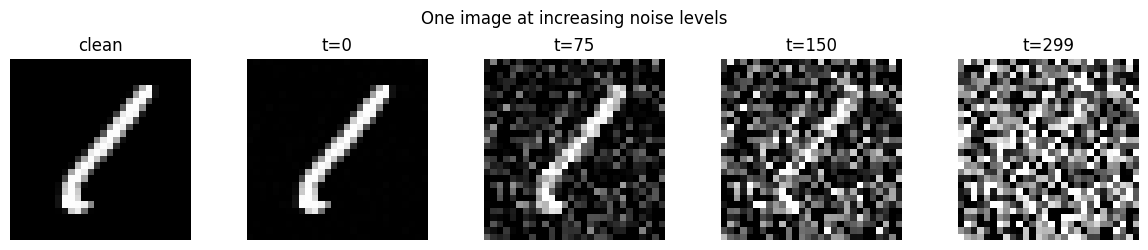

In [5]:
def q_sample(x0: torch.Tensor, t: torch.Tensor, noise: Optional[torch.Tensor] = None) -> torch.Tensor:
    assert x0.ndim == 4, f"Expected [B,C,H,W], got {tuple(x0.shape)}"
    assert t.shape == (x0.shape[0],), f"Expected [B], got {tuple(t.shape)}"
    assert t.device == x0.device == schedule["sqrt_alpha_bars"].device
    if noise is None: noise = torch.randn_like(x0)
    assert noise.shape == x0.shape and noise.device == x0.device
    xt = extract(schedule["sqrt_alpha_bars"], t, x0.shape)*x0 + extract(schedule["sqrt_one_minus_alpha_bars"], t, x0.shape)*noise
    assert xt.shape == x0.shape
    return xt

x_demo = real_images[:1].to(device)
levels = [0, NUM_TIMESTEPS//4, NUM_TIMESTEPS//2, NUM_TIMESTEPS-1]
fixed_noise = torch.randn_like(x_demo)
noisy = [q_sample(x_demo, torch.tensor([step], device=device), fixed_noise)[0,0].cpu() for step in levels]
fig, axes = plt.subplots(1, 5, figsize=(12, 2.5))
axes[0].imshow(x_demo[0,0].cpu(), cmap="gray", vmin=-1, vmax=1); axes[0].set_title("clean")
for ax, im, step in zip(axes[1:], noisy, levels): ax.imshow(im, cmap="gray", vmin=-1, vmax=1); ax.set_title(f"t={step}")
for ax in axes: ax.axis("off")
plt.suptitle("One image at increasing noise levels"); plt.tight_layout(); plt.show()
assert q_sample(real_images[:2].to(device), torch.tensor([0, NUM_TIMESTEPS//2], device=device)).shape == (2,1,28,28)

## 6. Sinusoidal timestep embeddings

Sinusoids encode a scalar timestep at multiple frequencies. An MLP projects the embedding; every residual block maps it to a per-channel bias that is broadcast over image height and width.

In [6]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim: int): super().__init__(); self.dim = dim
    def forward(self, t: torch.Tensor) -> torch.Tensor:
        assert t.ndim == 1
        half = self.dim // 2
        freq = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / max(half-1, 1))
        phase = t.float()[:, None] * freq[None, :]
        emb = torch.cat([phase.sin(), phase.cos()], dim=-1)
        return F.pad(emb, (0,1)) if self.dim % 2 else emb

class TimeResidualBlock(nn.Module):
    def __init__(self, cin: int, cout: int, time_dim: int):
        super().__init__()
        self.conv1=nn.Conv2d(cin,cout,3,padding=1); self.norm1=nn.GroupNorm(8,cout)
        self.conv2=nn.Conv2d(cout,cout,3,padding=1); self.norm2=nn.GroupNorm(8,cout)
        self.time_proj=nn.Linear(time_dim,cout)
        self.skip=nn.Identity() if cin==cout else nn.Conv2d(cin,cout,1)
    def forward(self,x:torch.Tensor,te:torch.Tensor)->torch.Tensor:
        h=self.norm1(self.conv1(x)); h=h+self.time_proj(te)[:,:,None,None]
        h=F.silu(h); h=self.norm2(self.conv2(h))
        return F.silu(h+self.skip(x))

## 7. Compact timestep-conditioned U-Net

The encoder downsamples and saves features. The bottleneck processes the smallest feature map; the decoder upsamples and concatenates encoder features at matching resolutions. Skip connections carry fine digit structure across the downsampling path. Explicit target sizes preserve alignment. The output predicts noise and matches `[B,1,28,28]` exactly.

In [7]:
class SmallUNet(nn.Module):
    def __init__(self, base_channels: int = 32):
        super().__init__(); assert base_channels % 8 == 0
        c1,c2,c3=base_channels,2*base_channels,4*base_channels; td=4*base_channels
        self.time_mlp=nn.Sequential(SinusoidalTimeEmbedding(td),nn.Linear(td,td),nn.SiLU(),nn.Linear(td,td))
        self.input=nn.Conv2d(1,c1,3,padding=1); self.down1=TimeResidualBlock(c1,c1,td)
        self.ds1=nn.Conv2d(c1,c2,4,stride=2,padding=1); self.down2=TimeResidualBlock(c2,c2,td)
        self.ds2=nn.Conv2d(c2,c3,4,stride=2,padding=1)
        self.mid1=TimeResidualBlock(c3,c3,td); self.mid2=TimeResidualBlock(c3,c3,td)
        self.up2=TimeResidualBlock(c3+c2,c2,td); self.up1=TimeResidualBlock(c2+c1,c1,td)
        self.out_norm=nn.GroupNorm(8,c1); self.out=nn.Conv2d(c1,1,3,padding=1)
    def forward(self,x:torch.Tensor,t:torch.Tensor)->torch.Tensor:
        assert x.ndim==4 and tuple(x.shape[1:])==(1,28,28), f"Bad image shape {tuple(x.shape)}"
        assert t.shape==(x.shape[0],)
        te=self.time_mlp(t); x1=self.down1(self.input(x),te)       # B,c1,28,28
        x2=self.down2(self.ds1(x1),te)                             # B,c2,14,14
        h=self.mid2(self.mid1(self.ds2(x2),te),te)                 # B,c3,7,7
        h=F.interpolate(h,size=x2.shape[-2:],mode="nearest")
        h=self.up2(torch.cat([h,x2],dim=1),te)
        h=F.interpolate(h,size=x1.shape[-2:],mode="nearest")
        h=self.up1(torch.cat([h,x1],dim=1),te)
        out=self.out(F.silu(self.out_norm(h)))
        assert out.shape==x.shape, f"{tuple(out.shape)} != {tuple(x.shape)}"
        return out

model=SmallUNet(int(CONFIG["base_channels"])).to(device)
with torch.no_grad():
    assert model(torch.randn(2,1,28,28,device=device),torch.zeros(2,dtype=torch.long,device=device)).shape==(2,1,28,28)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 1139969


## 8. Reverse DDPM sampler

For epsilon prediction, the reverse mean is `(x[t] - beta[t]/sqrt(1-alpha_bar[t])*epsilon_theta)/sqrt(alpha[t])`. Add Gaussian noise scaled by posterior variance for `t>0`; omit it for the final transition. Sampling starts from standard Gaussian noise and visits timesteps in reverse.

Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

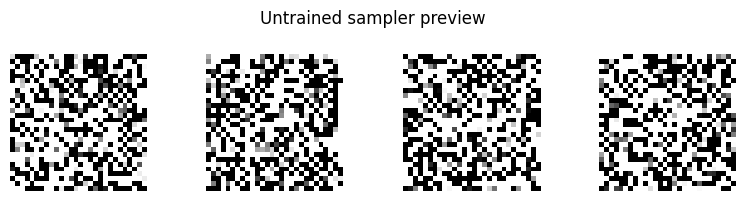

In [8]:
@torch.no_grad()
def sample(model: nn.Module, count: int, schedule: dict) -> torch.Tensor:
    model.eval(); dev=next(model.parameters()).device; T=len(schedule["betas"])
    x=torch.randn(count,1,28,28,device=dev)
    for step in tqdm(reversed(range(T)),total=T,desc="Sampling",leave=False):
        t=torch.full((count,),step,device=dev,dtype=torch.long)
        beta=extract(schedule["betas"],t,x.shape); alpha=extract(schedule["alphas"],t,x.shape)
        abar=extract(schedule["alpha_bars"],t,x.shape); eps=model(x,t)
        assert eps.shape==x.shape
        mean=(x-beta/torch.sqrt(1-abar)*eps)/torch.sqrt(alpha)
        if step>0: x=mean+torch.sqrt(extract(schedule["posterior_variance"],t,x.shape))*torch.randn_like(x)
        else: x=mean
    return x.clamp(-1,1)

preview=sample(model,4,schedule)
assert preview.shape==(4,1,28,28)
show_image_grid(preview,"Untrained sampler preview",nrow=4)

## 9. Training and resumable checkpoints

For each image, sample a timestep and Gaussian noise, create `x_t`, and minimize the standard `MSE(epsilon, epsilon_theta(x_t,t))`. Checkpoints preserve model and optimizer states, completed epoch, configuration, seed, and loss history. Loading maps tensors to the selected device.

Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1: mean noise-prediction MSE=0.13306


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

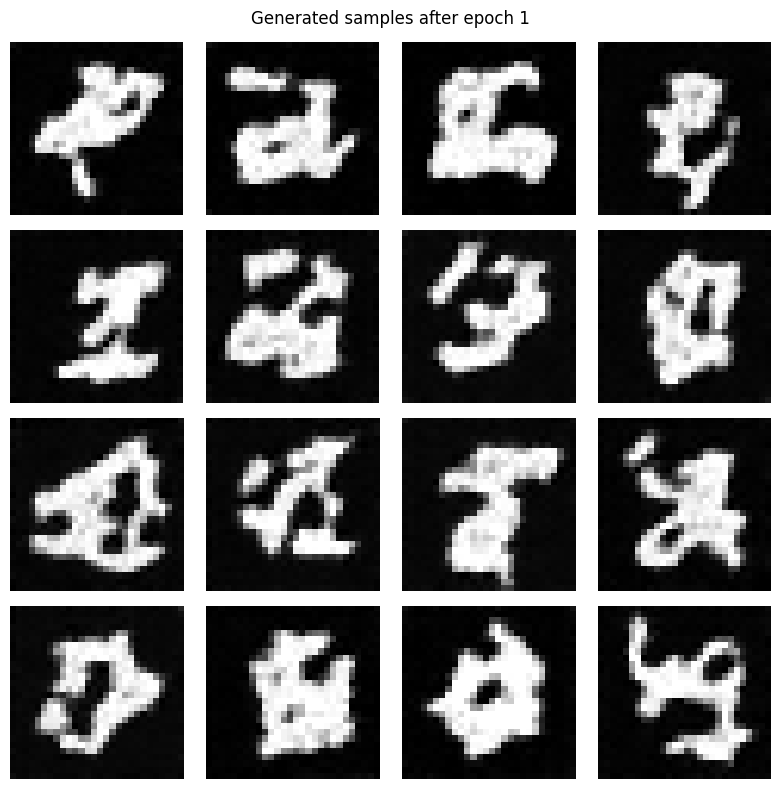

Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2: mean noise-prediction MSE=0.06410


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

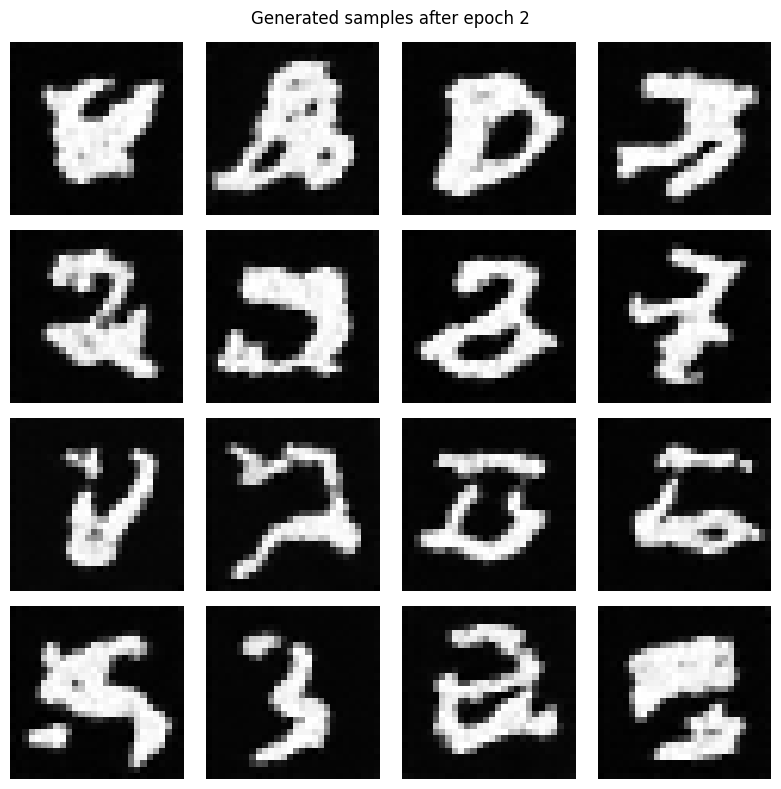

Epoch 3/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 3: mean noise-prediction MSE=0.05528


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

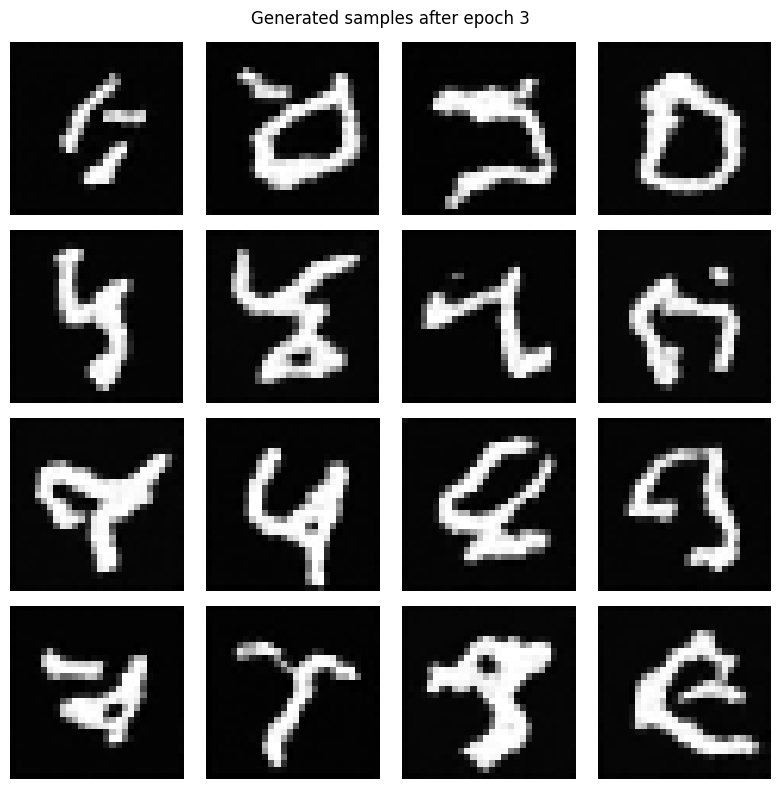

Epoch 4/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 4: mean noise-prediction MSE=0.05152


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

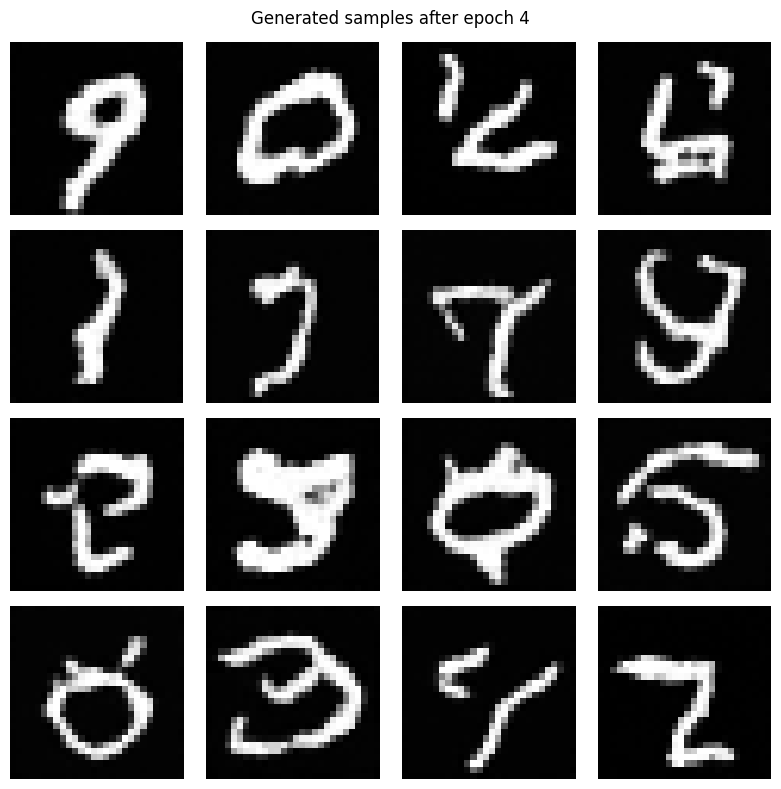

Epoch 5/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 5: mean noise-prediction MSE=0.04958


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

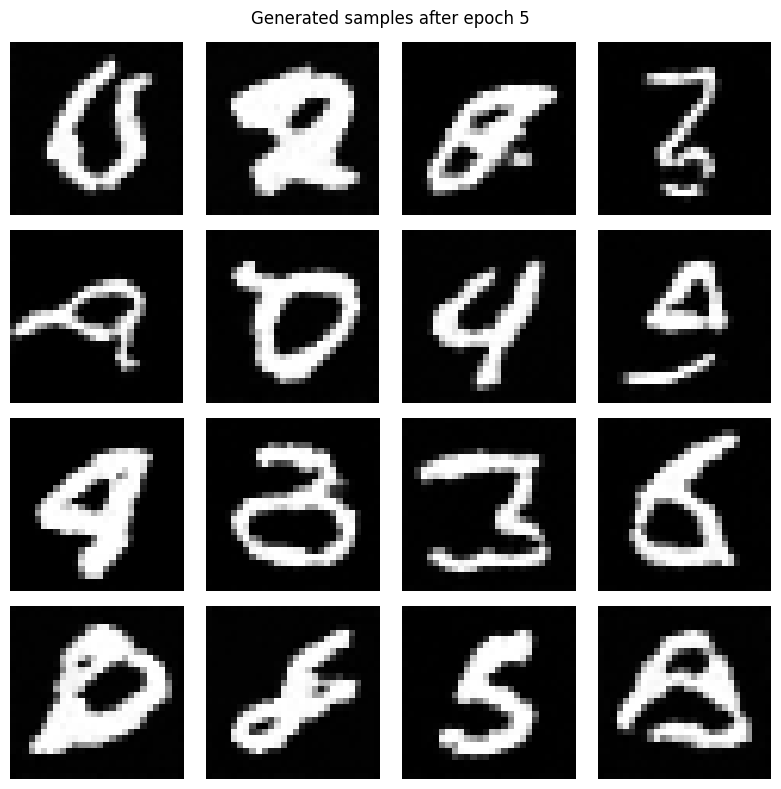

Epoch 6/20:   0%|          | 0/469 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6f2df258a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7a6f2df258a0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

Epoch 6: mean noise-prediction MSE=0.04781


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

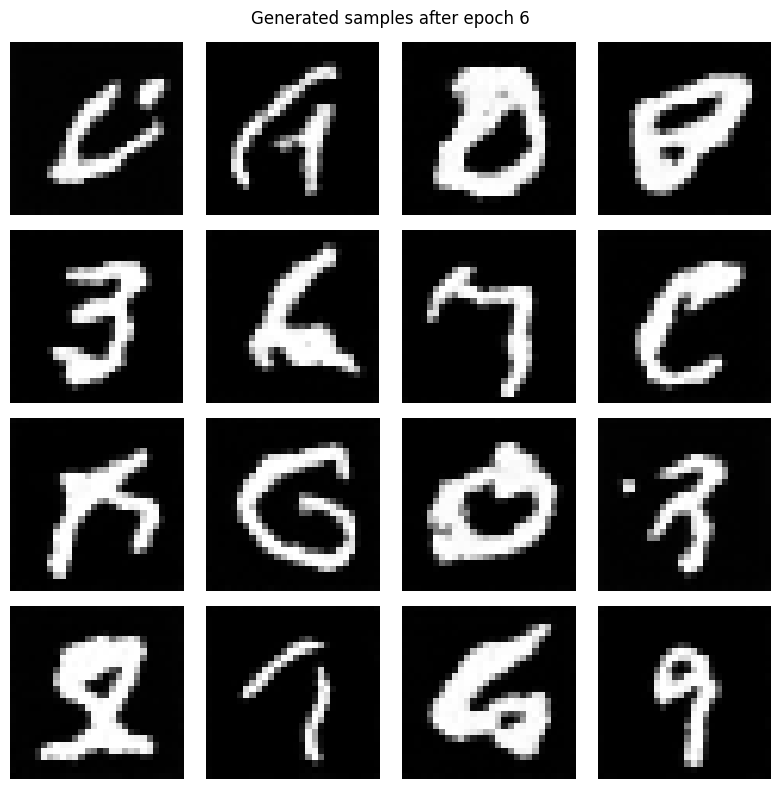

Epoch 7/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 7: mean noise-prediction MSE=0.04640


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

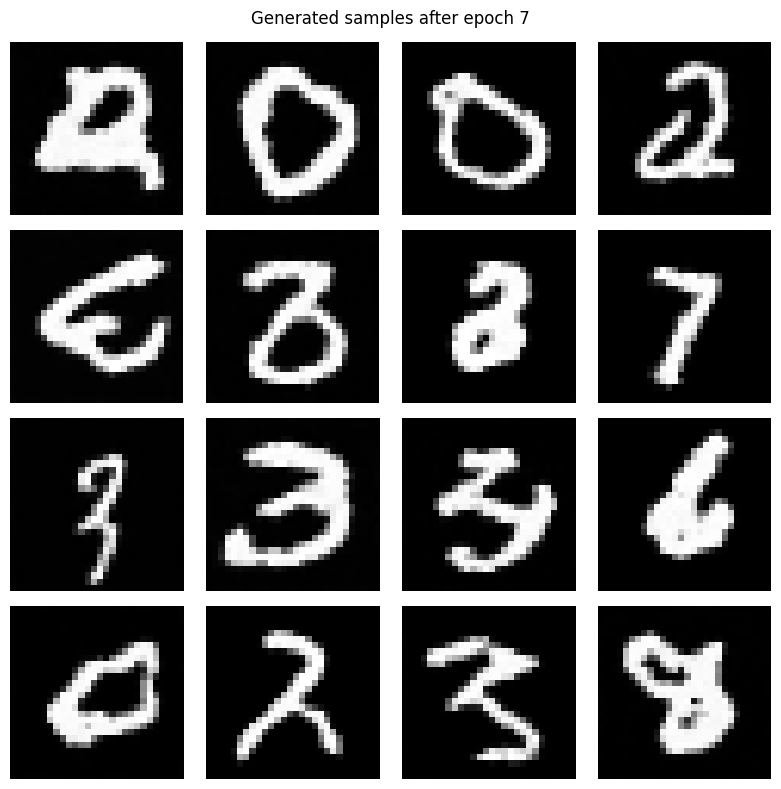

Epoch 8/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 8: mean noise-prediction MSE=0.04561


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

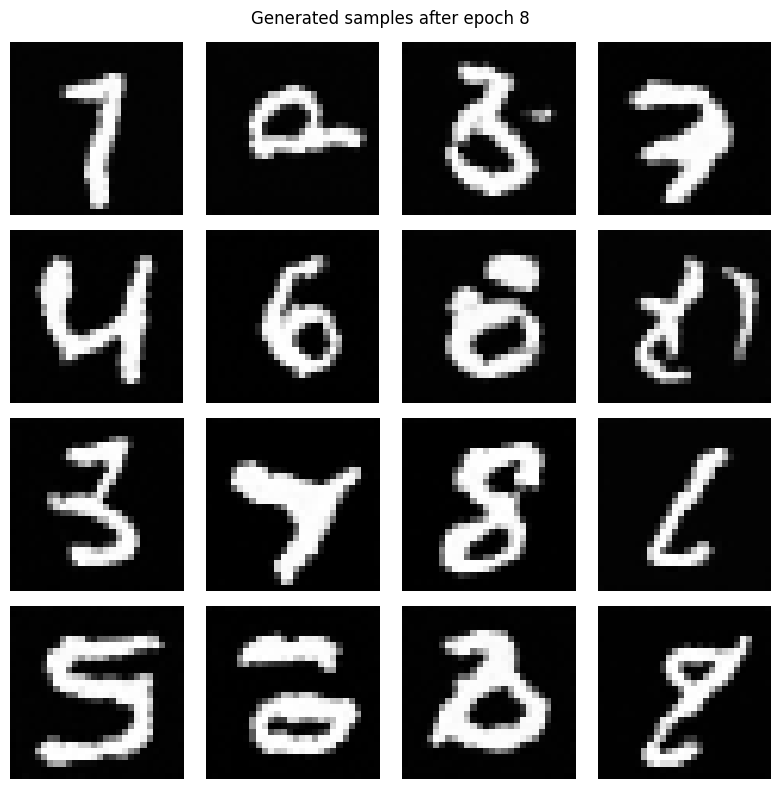

Epoch 9/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 9: mean noise-prediction MSE=0.04449


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

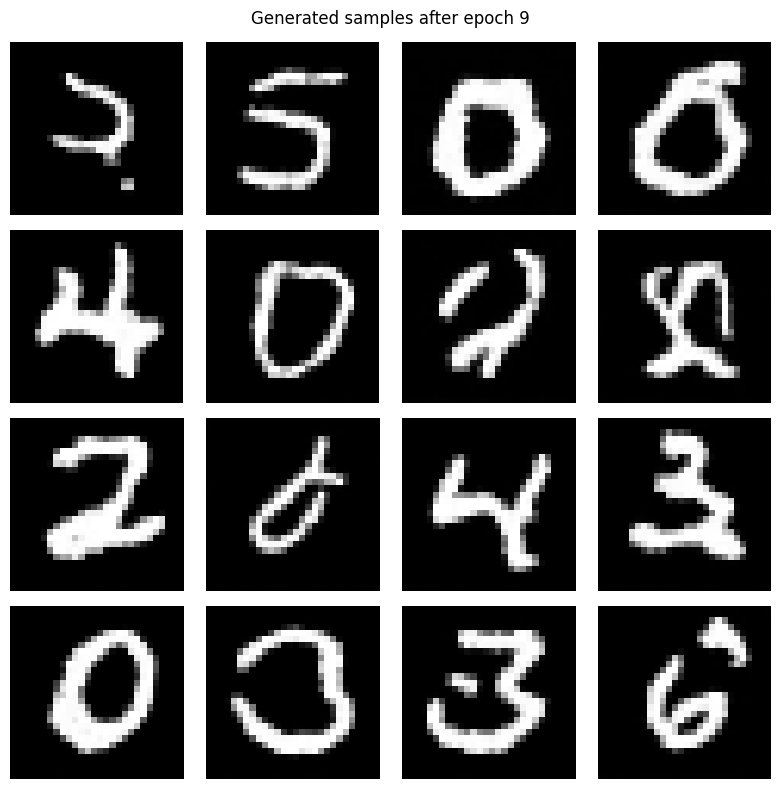

Epoch 10/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 10: mean noise-prediction MSE=0.04431


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

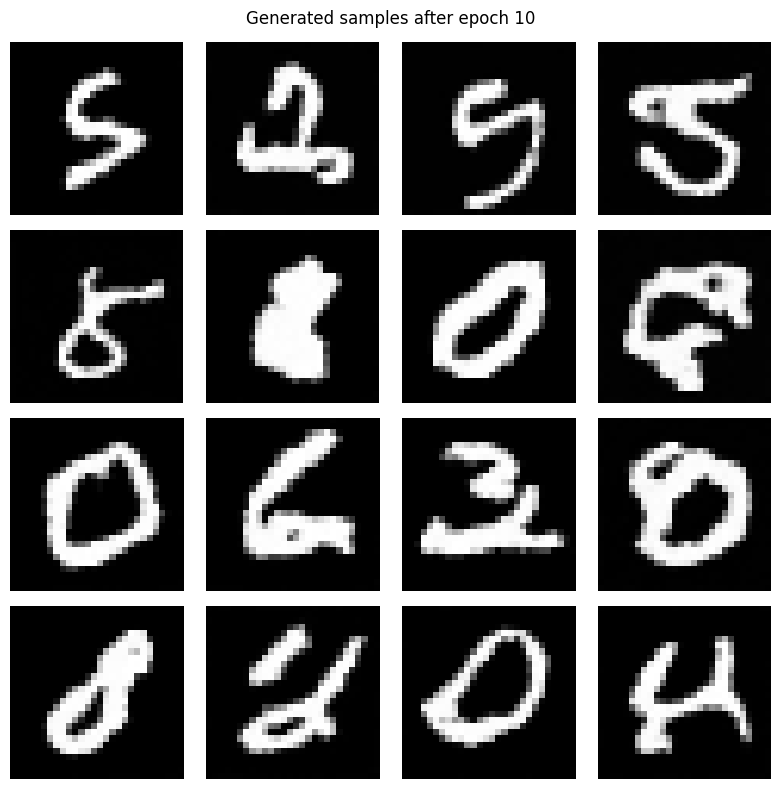

Epoch 11/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 11: mean noise-prediction MSE=0.04373


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

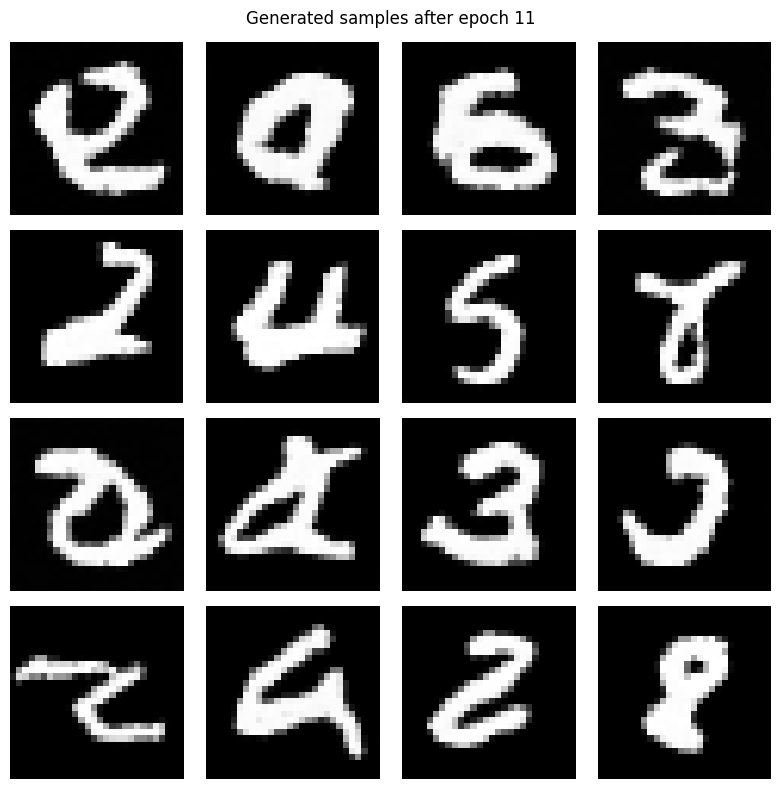

Epoch 12/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 12: mean noise-prediction MSE=0.04296


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

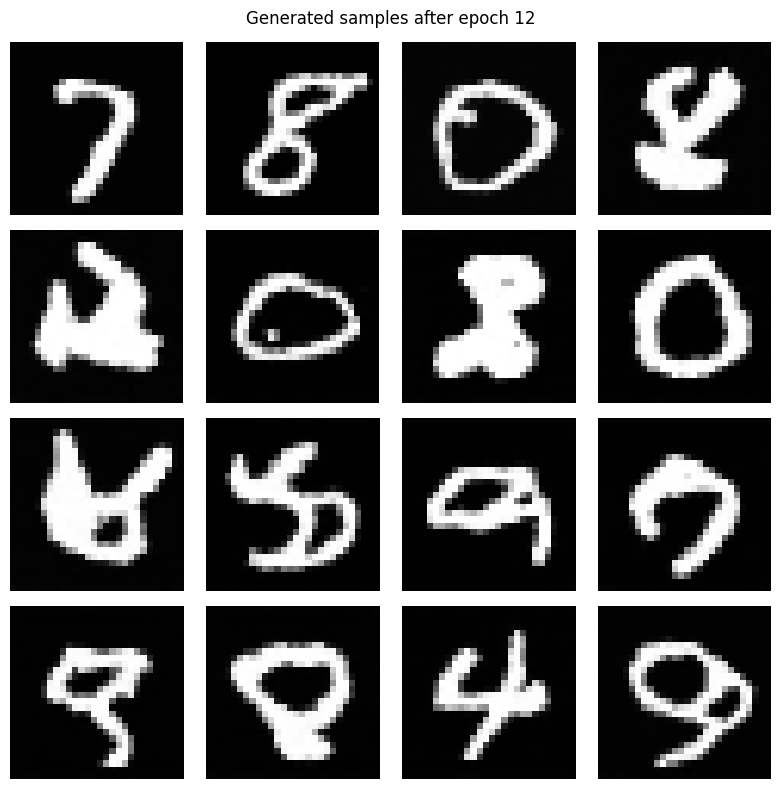

Epoch 13/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 13: mean noise-prediction MSE=0.04251


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

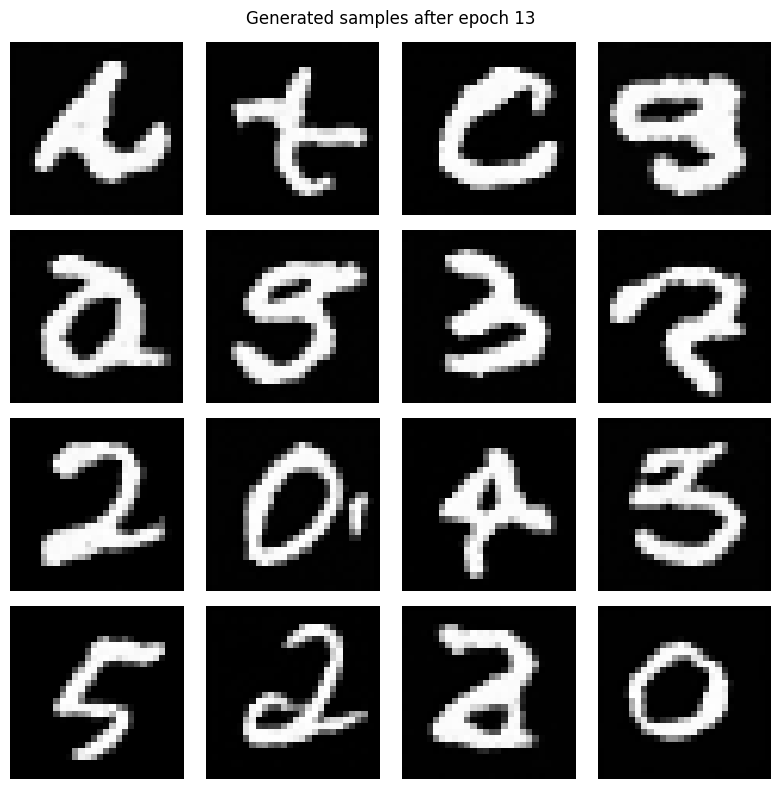

Epoch 14/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 14: mean noise-prediction MSE=0.04241


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

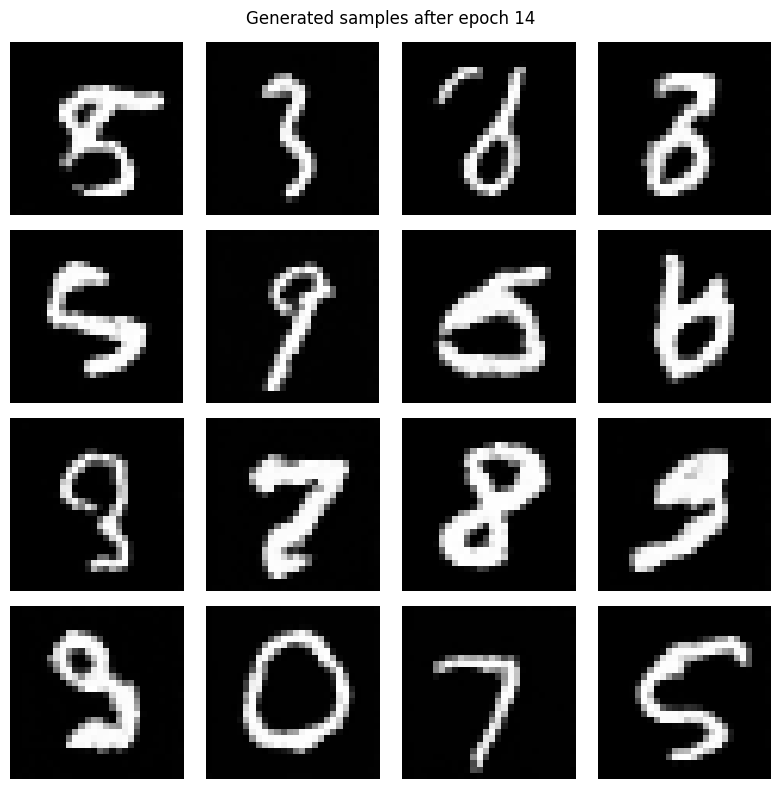

Epoch 15/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 15: mean noise-prediction MSE=0.04172


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

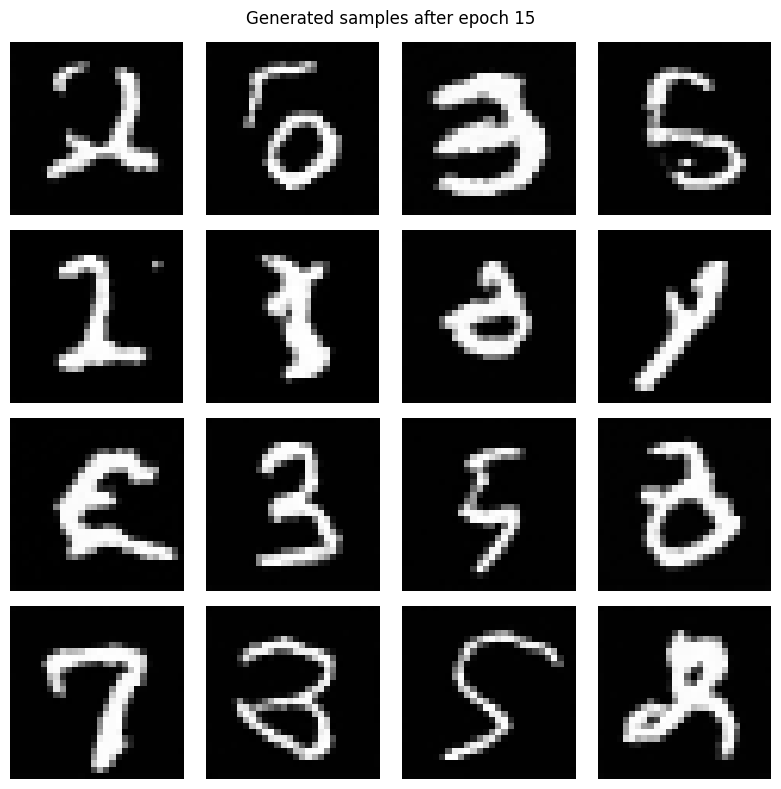

Epoch 16/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 16: mean noise-prediction MSE=0.04159


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

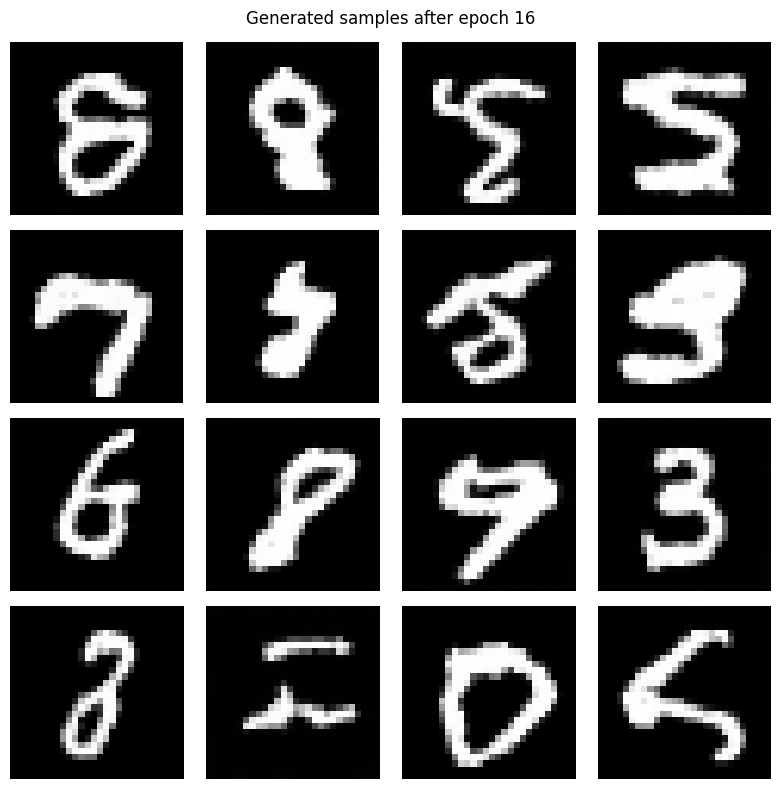

Epoch 17/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 17: mean noise-prediction MSE=0.04143


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

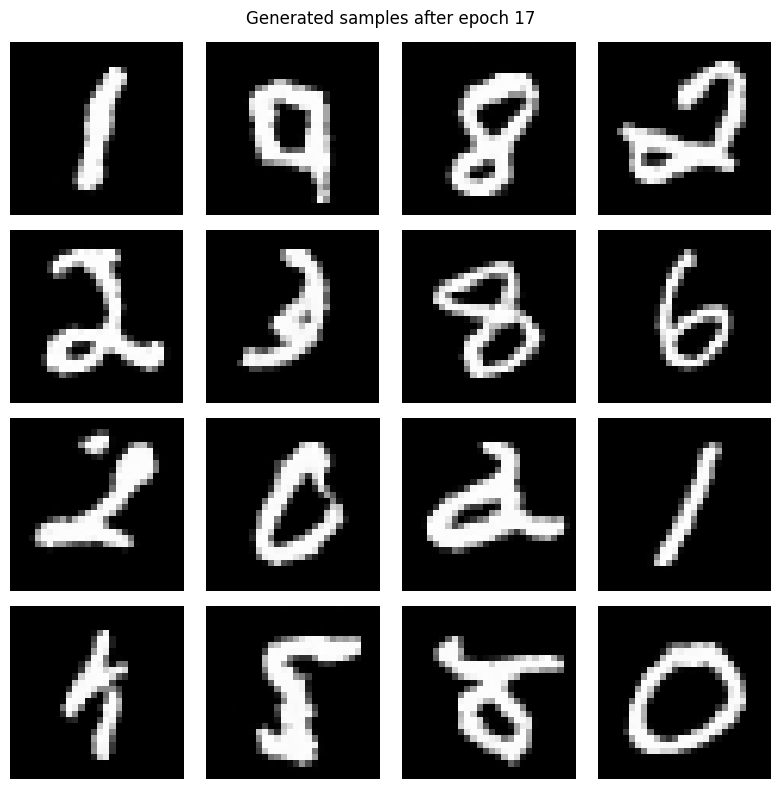

Epoch 18/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 18: mean noise-prediction MSE=0.04120


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

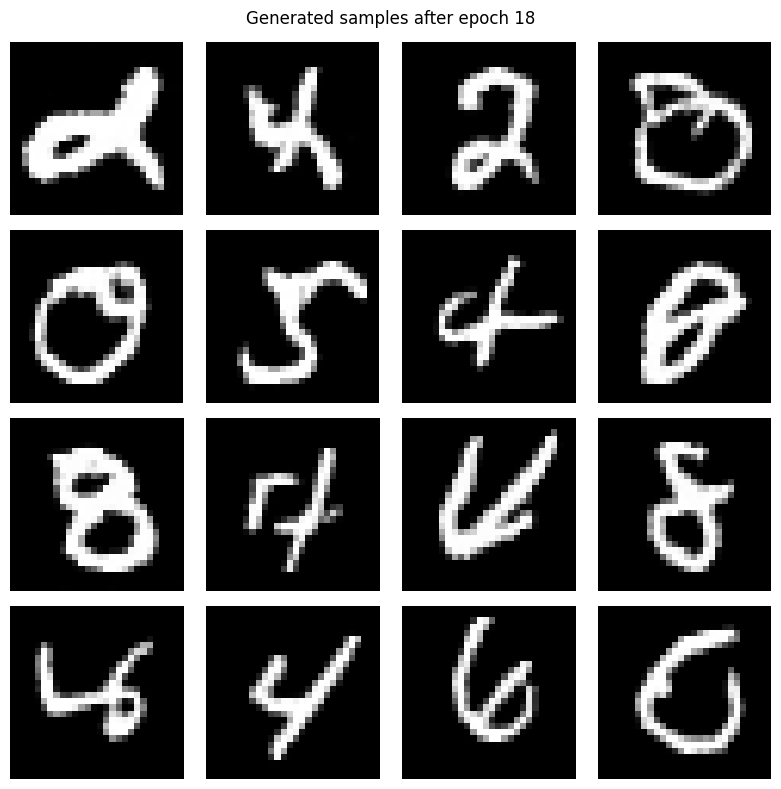

Epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 19: mean noise-prediction MSE=0.04094


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

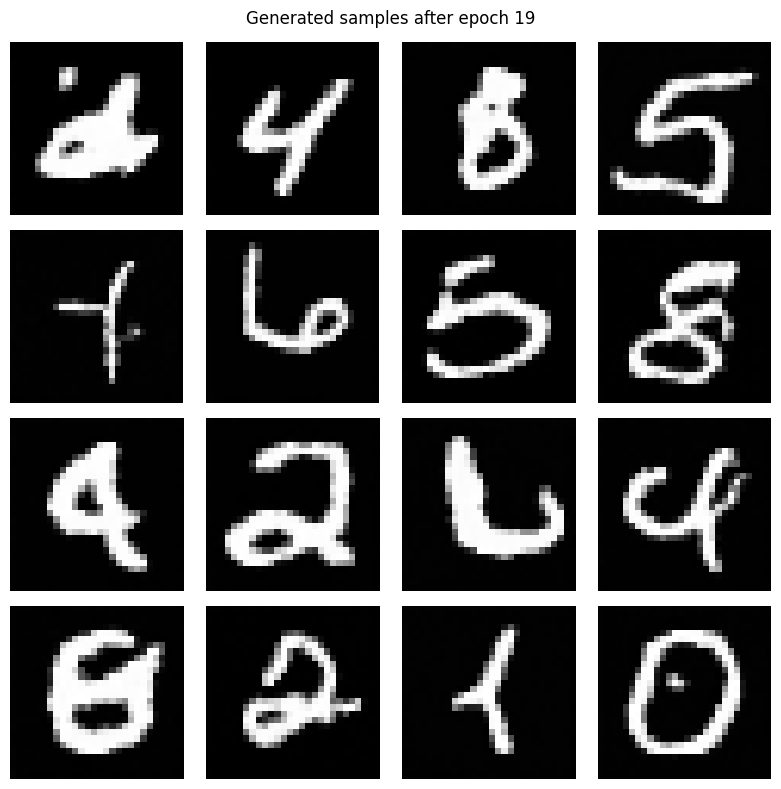

Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 20: mean noise-prediction MSE=0.04074


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

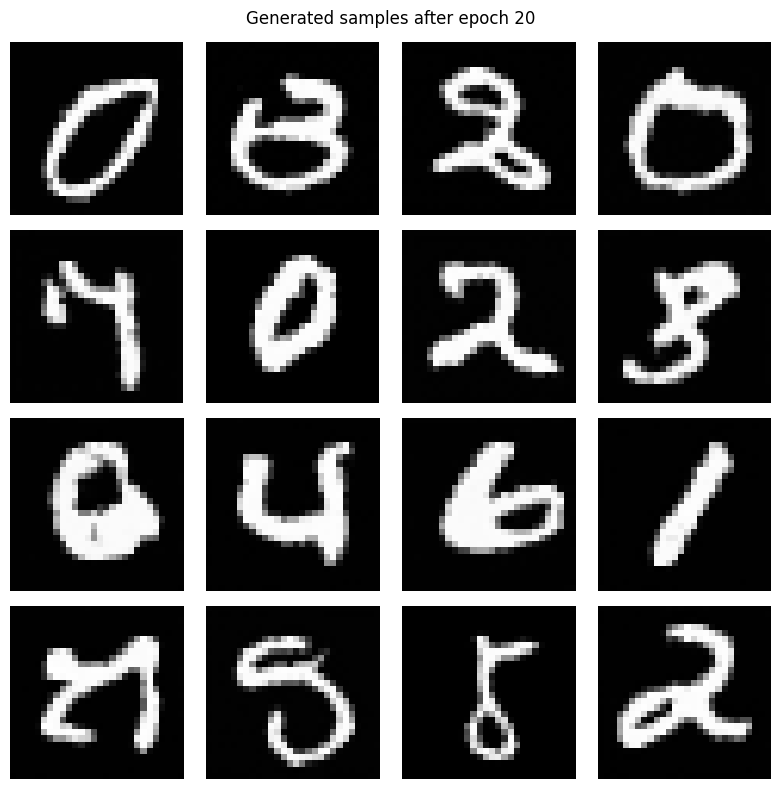

Training loop finished; this does not guarantee sample quality.


In [9]:
optimizer=torch.optim.AdamW(model.parameters(),lr=float(CONFIG["learning_rate"]))
start_epoch=0; loss_history=[]
if CONFIG["resume"] and CHECKPOINT_PATH.exists():
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device,weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"]); optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch=int(checkpoint["epoch"]); loss_history=list(checkpoint.get("loss_history",[]))
    print("Resumed at epoch",start_epoch)
elif CONFIG["resume"]: print("Checkpoint missing; starting fresh.")

@torch.no_grad()
def save_training_samples(epoch:int)->None:
    was_training=model.training; images=sample(model,int(CONFIG["sample_count"]),schedule)
    show_image_grid(images,f"Generated samples after epoch {epoch}")
    if was_training: model.train()

def save_checkpoint(epoch:int,mean_loss:float)->None:
    torch.save({"epoch":epoch,"model_state_dict":model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),"config":dict(CONFIG),"seed":SEED,
        "mean_loss":mean_loss,"loss_history":list(loss_history)},CHECKPOINT_PATH)

for epoch in range(start_epoch,int(CONFIG["epochs"])):
    model.train(); total=0.; batches=0
    iterator=tqdm(train_loader,desc=f"Epoch {epoch+1}/{CONFIG['epochs']}",leave=True,
        disable=not bool(CONFIG["show_progress"]))
    for x0,_ in iterator:
        x0=x0.to(device,non_blocking=True); b=x0.shape[0]
        t=torch.randint(0,NUM_TIMESTEPS,(b,),device=device,dtype=torch.long)
        noise=torch.randn_like(x0); xt=q_sample(x0,t,noise); predicted=model(xt,t)
        assert predicted.shape==noise.shape
        loss=F.mse_loss(predicted,noise)
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        total+=loss.item(); batches+=1; iterator.set_postfix(loss=f"{loss.item():.4f}")
    mean_loss=total/max(batches,1); loss_history.append(mean_loss); done=epoch+1
    save_checkpoint(done,mean_loss)
    print(f"Epoch {done}: mean noise-prediction MSE={mean_loss:.5f}")
    if done % int(CONFIG["sample_every_epochs"])==0: save_training_samples(done)
print("Training loop finished; this does not guarantee sample quality.")

## 10. Loss and final generated samples

The loss is an average pixelwise noise-prediction objective. A decreasing loss does not guarantee perfect digits: sample quality also depends on model capacity, training duration, noise schedule, and the reverse process. Inspect grids as well as the scalar loss.

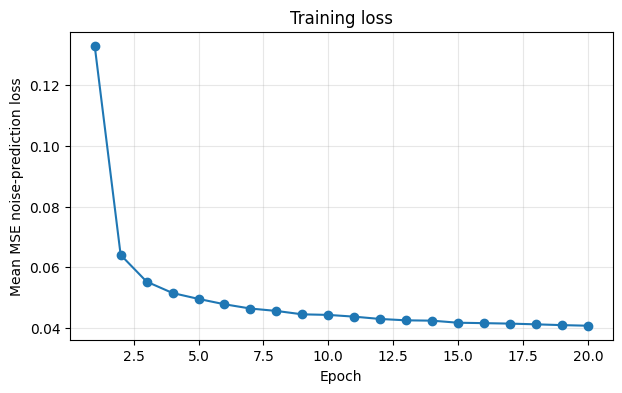

Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

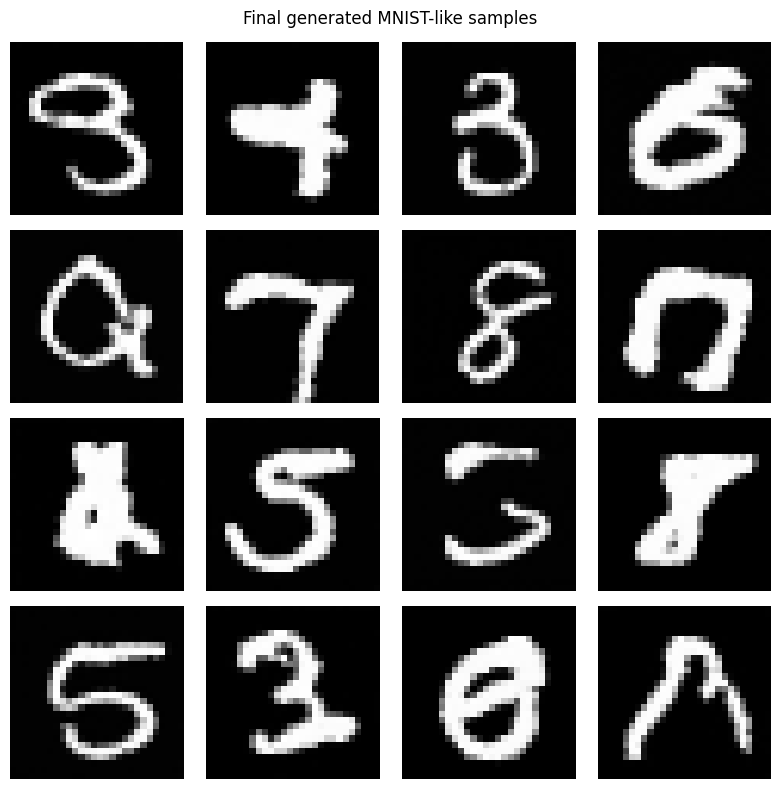

In [10]:
if loss_history:
    plt.figure(figsize=(7,4)); plt.plot(range(1,len(loss_history)+1),loss_history,marker="o")
    plt.xlabel("Epoch"); plt.ylabel("Mean MSE noise-prediction loss"); plt.title("Training loss")
    plt.grid(alpha=.3); plt.show()
else: print("No training history yet; run the training cell first.")
final_samples=sample(model,int(CONFIG["sample_count"]),schedule)
show_image_grid(final_samples,"Final generated MNIST-like samples")

## 11. Compare real, forward-noised, and generated images

The noised row uses one common timestep for visibility. Training itself samples independent timesteps per example.

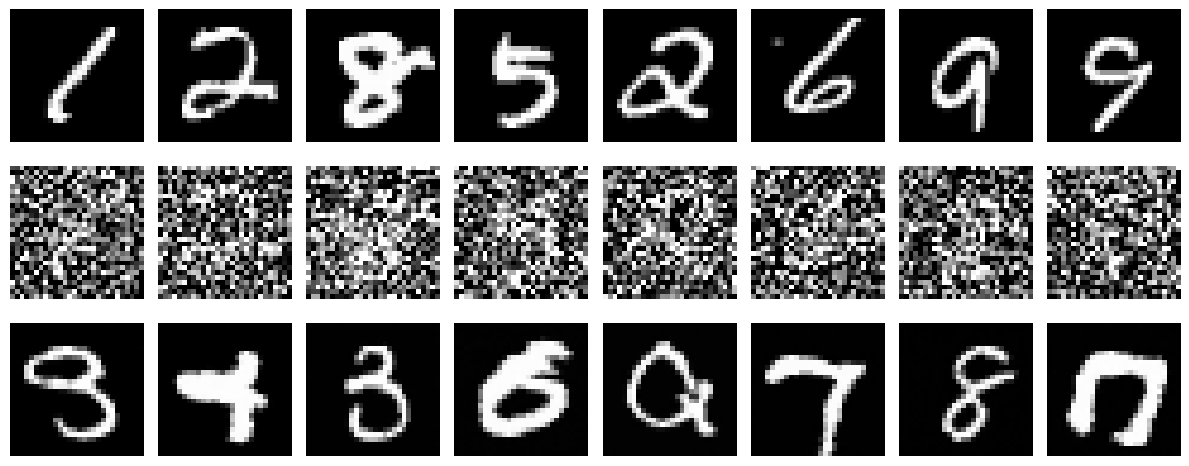

In [11]:
n=8; real=real_images[:n].to(device)
t_vis=torch.full((n,),NUM_TIMESTEPS*3//4,device=device,dtype=torch.long)
noised=q_sample(real,t_vis); generated=final_samples[:n]
fig,axes=plt.subplots(3,n,figsize=(n*1.5,5))
for r,(imgs,label) in enumerate([(real,"Real"),(noised,f"Noised (t={int(t_vis[0])})"),(generated,"Generated")]):
    for c in range(n):
        axes[r,c].imshow(imgs[c,0].detach().cpu().clamp(-1,1),cmap="gray",vmin=-1,vmax=1); axes[r,c].axis("off")
    axes[r,0].set_ylabel(label,rotation=0,labelpad=45,va="center")
plt.tight_layout(); plt.show()

## 12. Troubleshooting and verification checklist

- **Shape mismatches:** images must be `[B,1,28,28]`, timesteps integer `[B]`, coefficients broadcast as `[B,1,1,1]`; skip tensors need matching height and width.
- **CUDA out of memory:** reduce `batch_size`; if needed reduce `base_channels` (keep divisible by 8) or `sample_count`.
- **Exploding or stagnant loss:** verify `[-1,1]` normalization, a reasonable learning rate, varied timesteps, and that the target is precisely the noise used in `q_sample`. Lower the learning rate if loss is non-finite.
- **Poor samples:** train longer, inspect saved grids, and check forward/reverse schedules and final-step noise handling. A compact model can produce imperfect digits.

**Checklist:** (1) use the cumulative forward equation with per-image timesteps; (2) train against that same sampled epsilon with MSE; (3) use the epsilon-parameterized reverse mean with coefficients at the current timestep; (4) add posterior noise only when `t>0`; (5) keep tensors and schedule on the same device.